


# CSL304 Lab: Bellman equation and Value Iteration

**Please read before you start**
-Attendece is mendatory to submit this assignment.
- This assignmetn is very simple you just have to reuse the codes.
- This assignment is for your own self-assessment. Try to solve it on your own, without ChatGPT, Copilot, Gemini or any other AI tool, and without copying from friends. **The point is to check that your own brain can solve it when there is no AI around.**
-Beleive in yourself bucasue you guys have world toughest exam.
- You do not have to write new code. Understand the code of Part 1, reuse it, and solve the new situation in Part 2.
- First go through the explanation and the example (Part 1). After that, do the questions (Part 2).
-Last but not least please edit the file name with your roll no before submitting the file.

## Explanation: Bellman equation and Value Iteration

The value `V(s)` of a place is the **average cost to reach the goal** from that place. For an action `a`, the Q-value is the average of *cost + V of the place where we land*. The Bellman equation says the place takes the best (smallest) Q-value.

$$Q(s,a) = \sum_{s'} T(s,a,s')\,\big[\,C(s,a,s') + V(s')\,\big] \qquad\qquad V(s) = \min_a Q(s,a)$$

### Pseudo code (Value Iteration)

```
V0(s) = 0 for every place s                         (first guess)
n = 0
repeat
    n = n + 1
    for every place s that is not the goal:
        for every action a of s:
            Qn(s, a) = sum over s' of  T(s,a,s') * ( C(s,a,s') + V(n-1)(s') )
        Vn(s)     = min over a of Qn(s, a)          (Bellman equation)
        policy(s) = the action a that gave this min
    residual = max over s of | Vn(s) - V(n-1)(s) |
until residual < epsilon                            (values stopped changing)
```

## Part 1: sample (slide 10, a small map)

- At **P** there are two actions. `a` costs 5: with chance 0.6 we come back to P, with chance 0.4 we go to R. `b` costs 10: with chance 0.5 we go to S, with chance 0.5 we go to T.
- **R, S, T** have one action `c` that costs 1 and goes to the goal **G**.

First we write the map in code, then the loop of the pseudo code.

In [1]:
N = 5                                   # places: 0=P, 1=R, 2=S, 3=T, 4=G
GOAL = 4
names = ["P", "R", "S", "T", "G"]

# the map: every row is (place, action, probability, lands in, cost)
edges = [
    (0, "a", 0.6, 0, 5),                # at P, action a: with 0.6 back to P, cost 5
    (0, "a", 0.4, 1, 5),                # at P, action a: with 0.4 to R, cost 5
    (0, "b", 0.5, 2, 10),               # at P, action b: with 0.5 to S, cost 10
    (0, "b", 0.5, 3, 10),               # at P, action b: with 0.5 to T, cost 10
    (1, "c", 1.0, 4, 1),                # at R, action c: to G, cost 1
    (2, "c", 1.0, 4, 1),                # at S, action c: to G, cost 1
    (3, "c", 1.0, 4, 1),                # at T, action c: to G, cost 1
]

Drawing the map (helper, just run it). Red text above a place means you stay in the same place.

In [2]:
import math
import matplotlib.pyplot as plt

def draw_map(edges, names, GOAL, pos=None, title=""):
    n = len(names)
    if pos is None:                         # no positions given, put the places on a circle
        pos = [(5 * math.sin(2 * math.pi * i / n), 5 * math.cos(2 * math.pi * i / n)) for i in range(n)]
    plt.figure(figsize=(12, 7))
    for (s, a, prob, nxt, cost) in edges:
        label = a + " " + str(prob) + ", " + str(cost)
        x1, y1 = pos[s]
        x2, y2 = pos[nxt]
        if s == nxt:                        # stays in the same place
            plt.text(x1, y1 + 0.8, "↺ " + label, ha="center", color="red")
        else:
            plt.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->",
                         shrinkA=28, shrinkB=28, connectionstyle="arc3,rad=0.15"))
            plt.text((x1 + x2) / 2 + 0.08 * (y2 - y1), (y1 + y2) / 2 - 0.08 * (x2 - x1), label,
                     ha="center", va="center", backgroundcolor="white")
    for i in range(n):
        plt.scatter(pos[i][0], pos[i][1], s=2600, color="gold" if i == GOAL else "white",
                    edgecolors="black", zorder=3)
        plt.text(pos[i][0], pos[i][1], names[i].replace(" ", "\n"), ha="center", va="center", fontsize=9, zorder=4)
    plt.xlim(min(p[0] for p in pos) - 1.5, max(p[0] for p in pos) + 1.5)
    plt.ylim(min(p[1] for p in pos) - 1.5, max(p[1] for p in pos) + 1.5)
    plt.axis("off")
    plt.title(title)
    plt.show()

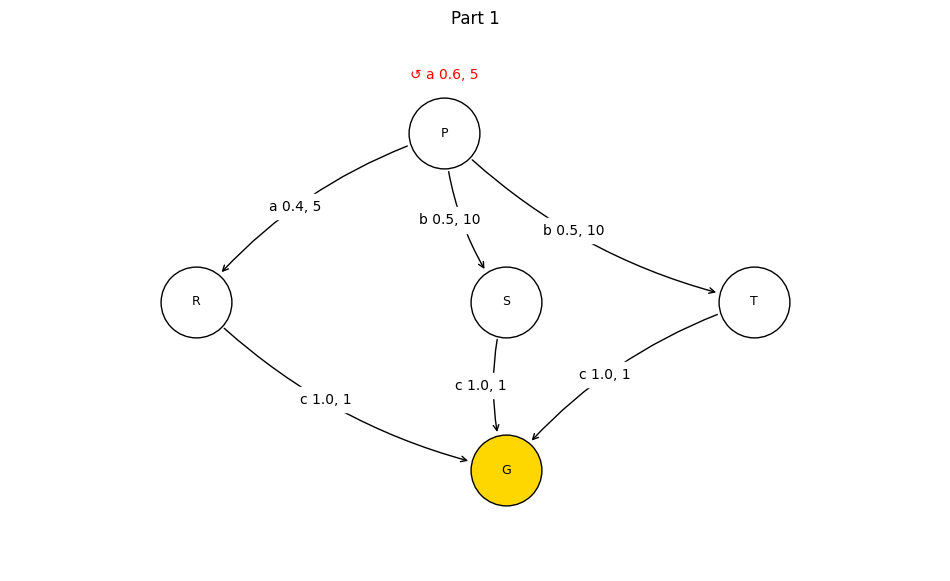

In [3]:
pos = [(3, 4), (1, 1.5), (3.5, 1.5), (5.5, 1.5), (3.5, -1)]    # P, R, S, T, G
draw_map(edges, names, GOAL, pos, title="Part 1")

In [4]:
V = [0] * N                                           # V0: first guess, 0 everywhere
epsilon = 0.001

n = 0
while True:
    n = n + 1
    newV = V.copy()                                   # Vn is built from V(n-1)
    policy = {}
    for s in range(N):
        if s == GOAL:
            continue                                  # value of the goal stays 0
        Q = {}                                        # Q[a] for place s
        for (place, a, prob, nxt, cost) in edges:
            if place == s:                            # only the rows of this place
                Q[a] = Q.get(a, 0) + prob * (cost + V[nxt])
        newV[s] = min(Q.values())                     # Bellman equation: the smallest Q
        policy[s] = min(Q, key=Q.get)                 # the action that gave the smallest Q

    residual = max(abs(newV[s] - V[s]) for s in range(N))
    V = newV
    print("n =", n, ":", [round(v, 2) for v in V])
    if residual < epsilon:                            # values stopped changing
        break

for s in range(N):
    if s != GOAL:
        print(names[s], ": V =", round(V[s], 2), ", best action =", policy[s])

n = 1 : [5.0, 1.0, 1.0, 1.0, 0]
n = 2 : [8.4, 1.0, 1.0, 1.0, 0]
n = 3 : [10.44, 1.0, 1.0, 1.0, 0]
n = 4 : [11.0, 1.0, 1.0, 1.0, 0]
n = 5 : [11.0, 1.0, 1.0, 1.0, 0]
P : V = 11.0 , best action = b
R : V = 1.0 , best action = c
S : V = 1.0 , best action = c
T : V = 1.0 , best action = c


---
## Part 2: Questions (situation)

Your CSL304 (AI) paper has just finished in the **Exam Hall** and you are very hungry. You want to get food in the least average time (in minutes). You are done the moment you have your food. Call this place **Food**, it is the goal.

- From the Exam Hall you can take the `stairs` down to the **Campus Canteen** (3 min). Or take the `lift` down to the **Parking**: with chance 0.6 the lift comes and you reach the Parking in 1 min, with chance 0.4 the lift is busy, 2 min pass and you are still in the Exam Hall.
- The food in the Campus Canteen is not good, so you don't eat there. From there you can `walk` to the **LDC Cafe** (4 min) or `cut` through to the Parking (2 min).
- At the LDC Cafe you can `order`: with chance 0.6 the food comes in 10 min, with chance 0.4 the queue is long, 6 min pass and you are still waiting there. Or you can `leave` and walk to the **Road** (4 min).
- At the Parking you can `walk` to the Road (2 min). Or take your `cycle` to **Gate 2**: with chance 0.7 you reach in 3 min, with chance 0.3 the tyre is flat, 4 min pass and you are still at the Parking.
- There is a cow standing on the Road. You can `walk`: with chance 0.7 you reach Gate 2 in 5 min, with chance 0.3 the cow chases you back to the Parking (4 min). Or take an `auto`: with chance 0.8 it drops you at the **Kahu Square Canteen** in 6 min, with chance 0.2 the cow blocks the auto, 6 min pass and you are still on the Road.
- At Gate 2 you `walk` out: with chance 0.9 the guard lets you go and you reach the Kahu Square Canteen in 3 min, with chance 0.1 you forgot your ID card and go to the **Hostel** to get it (5 min).
- From the Hostel you `walk` back to Gate 2 (6 min).
- At the Kahu Square Canteen you `eat`: the food is ready in 5 min.

Use the place names in bold as they are, and give the Exam Hall the number 0.

**(a)** Find all the places (states) in this situation. Write `N`, `GOAL`, `names` and the map `edges` (one row for every possible landing place).

**(b)** Reuse the Value Iteration code of Part 1 on your map. How many minutes do you need on average from the Exam Hall to get your food?

**(c)** What is the best action at the Exam Hall, Campus Canteen, LDC Cafe, Parking and Road? At the Exam Hall, stairs or lift, and why? Once you are at the LDC Cafe, should you wait in the queue or leave?

### (a) The places and the map

In [5]:
# Write your answer
N = 0                                   # number of places
GOAL = 0                                # number of the goal place
names = []                              # names of the places

# (place, action, probability, lands in, cost in minutes)
edges = [

]

In [6]:
# Check of your map (given, nothing to do): every place needs an action, and the probabilities of one action add up to 1
for s in range(N):
    if s == GOAL:
        continue
    actions = set(a for (place, a, prob, nxt, cost) in edges if place == s)
    assert len(actions) > 0, names[s] + " (place " + str(s) + ") has no action yet. Fill its rows."
    for a in actions:
        total = sum(prob for (place, b, prob, nxt, cost) in edges if place == s and b == a)
        assert abs(total - 1) < 0.0001, names[s] + ", action " + a + ": probabilities add up to " + str(total)
print("Map looks fine")

Map looks fine


Draw your map and check it with the story.

In [7]:
draw_map(edges, names, GOAL, title="Part 2: your map")

ValueError: min() iterable argument is empty

<Figure size 1200x700 with 0 Axes>

### (b) Value Iteration

In [ ]:
# Write your answer: reuse the Value Iteration code of Part 1 here


In [ ]:
# Self-check (should print True)
print(abs(V[0] - 16.27) < 0.02)

### (b) and (c) Your answers (double-click to edit)

- Average time from the Exam Hall: Write your answer
- Best actions (with the Q-values you compared): Write your answer
- Stairs or lift at the Exam Hall, and why: Write your answer
- At the LDC Cafe, wait or leave: Write your answer